<a href="https://colab.research.google.com/github/edwinfernandoochoaarenas-maker/Senderos-del-Zipa-TRL5/blob/main/Predictive_Analytics_Phase1_Exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# National Open and Distance University - UNAD
## School of Basic Sciences, Technology and Engineering (ECBTI)
### Specialization in Analytics and Data Science

---

* **Course:** Predictive Analytics (Code: 203008078)
* **Phase:** Phase 1 – Exploration (Exploratory Data Analysis - EDA)
* **Student:** Edwin Fernando Ochoa Arenas
* **Date:** October 2026

---

### Notebook Description:
This notebook contains the practical execution for **Phase 1: Exploration**, focusing on data loading, data cleaning, basic feature engineering, and descriptive analysis of the transactional dataset (`Appendix 1 - Database.csv`), strictly adhering to the course academic guidelines and web-conference recommendations.

---

### **STEP 2: IMPORT LIBRARIES AND LOAD DATA**

In [13]:

# Import essential data science libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt




In [14]:


# Define the file path (ensure 'Appendix 1 - Database.csv' is uploaded to Colab)
file_path = 'Appendix 1 - Database.csv'



In [15]:
# Load the dataset using ISO-8859-1 encoding to handle special characters correctly
df = pd.read_csv(file_path, encoding='ISO-8859-1')



In [16]:
# Standardize headers: strip spaces and convert to lowercase (as required by the Starter Kit)
df.columns = df.columns.str.strip().str.lower()

In [17]:
# Print confirmation and initial dimensions of the dataset
print("Dataset successfully loaded")
print(f"Total rows (transactions): {df.shape[0]:,}")
print(f"Total columns (variables): {df.shape[1]}")

Dataset successfully loaded
Total rows (transactions): 541,909
Total columns (variables): 8


In [18]:
# Display the first 3 rows to inspect the raw structure
df.head(3)

,invoiceno,stockcode,description,quantity,invoicedate,unitprice,customerid,country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom


### **STEP 3: INITIAL DATA INSPECTION**


In [8]:
# Check data types and non-null counts for each column
print("--- DATASET STRUCTURE & TYPES ---")
df.info()

--- DATASET STRUCTURE & TYPES ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 498916 entries, 0 to 498915
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    498916 non-null  object 
 1   StockCode    498916 non-null  object 
 2   Description  497489 non-null  object 
 3   Quantity     498915 non-null  float64
 4   InvoiceDate  498915 non-null  object 
 5   UnitPrice    498915 non-null  float64
 6   CustomerID   376551 non-null  float64
 7   Country      498915 non-null  object 
dtypes: float64(3), object(5)
memory usage: 30.5+ MB


### **STEP 4: DATA CLEANING & FILTERING**

In [20]:
# 1. Filter out returns, cancellations (Quantity <= 0) and invalid prices (UnitPrice <= 0)
df_clean = df[(df['quantity'] > 0) & (df['unitprice'] > 0)].copy()

# 2. Calculate how many rows were removed (Fixed syntax)
removed_rows = len(df) - len(df_clean)

# 3. Print cleaning summary
print(f"\n--- CLEANING RESULTS ---")
print(f"Original total rows: {len(df):,}")
print(f"Rows after filtering errors/returns: {len(df_clean):,}")
print(f"Total rows removed: {removed_rows:,}")

# 4. Check missing CustomerIDs in the cleaned subset
missing_cust = df_clean['customerid'].isnull().sum()
print(f"Transactions without CustomerID remaining: {missing_cust:,}")


--- CLEANING RESULTS ---
Original total rows: 541,909
Rows after filtering errors/returns: 530,104
Total rows removed: 11,805
Transactions without CustomerID remaining: 132,220


### **STEP 5: BASIC FEATURE ENGINEERING**

In [21]:



# 1. Create totalprice column (Quantity * UnitPrice) using vectorized operations
df_clean['totalprice'] = df_clean['quantity'] * df_clean['unitprice']

# 2. Convert invoicedate to proper datetime format for temporal analysis
df_clean['invoicedate'] = pd.to_datetime(df_clean['invoicedate'])

# Display confirmation and a preview of the new columns
print("--- FEATURE ENGINEERING COMPLETED ---")
print("New column 'totalprice' created successfully.")
print(f"Temporal span of data: from {df_clean['invoicedate'].min()} to {df_clean['invoicedate'].max()}")

# Show a sample of the updated dataframe
df_clean[['invoicedate', 'stockcode', 'quantity', 'unitprice', 'totalprice', 'customerid', 'country']].head(3)

--- FEATURE ENGINEERING COMPLETED ---
New column 'totalprice' created successfully.
Temporal span of data: from 2010-12-01 08:26:00 to 2011-12-09 12:50:00


,invoicedate,stockcode,quantity,unitprice,totalprice,customerid,country
0,2010-12-01 08:26:00,85123A,6,2.55,15.30,17850.0,United Kingdom
1,2010-12-01 08:26:00,71053,6,3.39,20.34,17850.0,United Kingdom
2,2010-12-01 08:26:00,84406B,8,2.75,22.00,17850.0,United Kingdom


### **STEP 6: DESCRIPTIVE ANALYTICS & AGGREGATIONS**



In [23]:
# 1. Calculate total gross revenue of the cleaned dataset
total_revenue = df_clean['totalprice'].sum()
print(f"--- GLOBAL METRICS ---")
print(f"Total Gross Revenue: ${total_revenue:,.2f}")

# 2. Identify Top Customers by total spending AND unique invoices (Starter Kit requirement)
top_customers = df_clean.groupby('customerid').agg(
    total_spend=('totalprice', 'sum'),
    unique_invoices=('invoiceno', 'nunique')
).reset_index()

# Sort by total spend descending and take the top 5
top_customers = top_customers.sort_values(by='total_spend', ascending=False).head(5)

print("\n--- TOP 5 CUSTOMERS BY REVENUE & INVOICES ---")
print(top_customers.to_string(index=False))

--- GLOBAL METRICS ---
Total Gross Revenue: $10,666,684.54

--- TOP 5 CUSTOMERS BY REVENUE & INVOICES ---
 customerid  total_spend  unique_invoices
    14646.0    280206.02               73
    18102.0    259657.30               60
    17450.0    194550.79               46
    16446.0    168472.50                2
    14911.0    143825.06              201


### **STEP 7: INVOICE TOTALS DISTRIBUTION (LOG-SCALE HISTOGRAM)
**

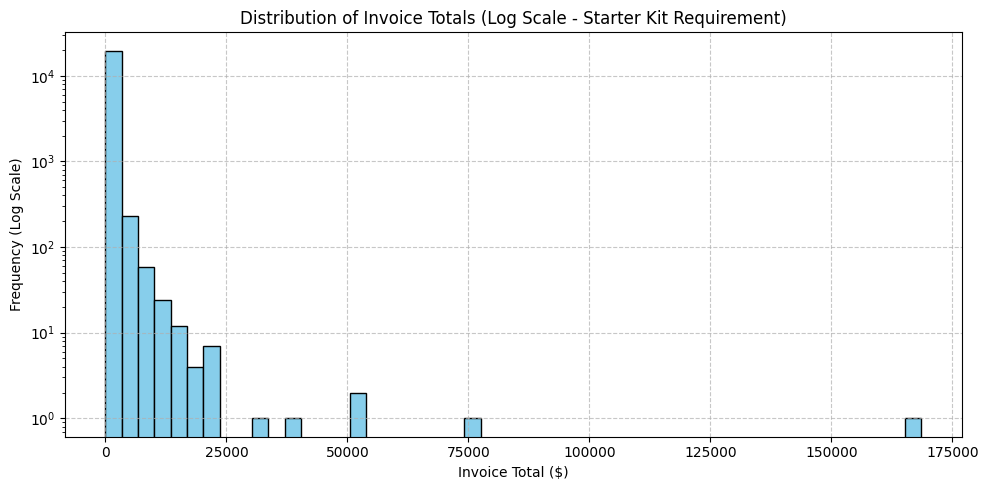

In [24]:


# 1. Aggregate total price per invoice (summing items for each invoiceno)
invoice_totals = df_clean.groupby('invoiceno')['totalprice'].sum()

# 2. Plot histogram with logarithmic scale as requested by the Starter Kit
plt.figure(figsize=(10, 5))
plt.hist(invoice_totals, bins=50, color='skyblue', edgecolor='black', log=True)

plt.title('Distribution of Invoice Totals (Log Scale - Starter Kit Requirement)')
plt.xlabel('Invoice Total ($)')
plt.ylabel('Frequency (Log Scale)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()

# Display the plot
plt.show()